# Project 3.6. Disorder in spatially extended systems

Given A a complex field, the complex Ginzburg-Lando (CGL) equation reads

$\boxed{\partial_tA=A+(1+i\alpha)\nabla^2A-(\beta-1)|A|^2A}$

The following figure shows the phase diagram of the two-dimensional CGL equation, found by Chaté and Manneville. Phase turbulence is observed between lines $L$ and $BF$, defect turbulence to the left of line $T$, and frozen states exist (approximately) to the fight of line $S_2$. Details are given in the text.

![Phase diagram of the two-dimensional CGL equation](../figures/Chaté-Manneville_Phase_Diagram.png)

In [1]:
# Common imports
%matplotlib inline
import time
from collections.abc import Callable

import numpy as np
import scipy.linalg as la
import scipy.sparse as sparse

import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.image import AxesImage
from IPython.display import HTML

PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#E69F00", "#F0E442"]
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (6.5, 4.2),
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.edgecolor": "#898781",
    "axes.linewidth": 0.9,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "axes.axisbelow": True,
    "animation.html": "jshtml",    # animations are rendered as interactive JavaScript widgets
    "animation.embed_limit": 60,   # in MB
})

# the random number generator
rng = np.random.default_rng(seed=2026)

# colormaps: sequential for u >= 0, diverging for signed fields, cyclic for phases
SEQ_CMAP = LinearSegmentedColormap.from_list("sequential", ["#f7f6f3", "#56B4E9", "#0072B2", "#0b2545"])
DIV_CMAP = LinearSegmentedColormap.from_list("diverging", ["#0072B2", "#f0efec", "#D55E00"])
PHASE_CMAP = "twilight"

# to draw a field u(x, t) as a space-time map
def show_spacetime(x: np.ndarray, t: np.ndarray, u: np.ndarray, ax: plt.Axes | None = None,
                   cmap=SEQ_CMAP, label: str | None = None, **kwargs) -> AxesImage:
    """Draw u[n, j] = u(x_j, t_n) as a map, with x horizontal and t increasing upwards."""
    ax = ax if ax is not None else plt.gca()
    image = ax.imshow(u, origin="lower", aspect="auto", cmap=cmap,
                      extent=(x[0], x[-1], t[0], t[-1]), **kwargs)
    ax.set(xlabel="$x$", ylabel="$t$")
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(True)
    ax.figure.colorbar(image, ax=ax, label=label, pad=0.02)
    return image

## Part 1: Fourrier Transform Solver

1.1. We write a class for the Gaussian $u_0(x)=U_0\exp(-((x-x_0)^2+(y-y_0)^2)/\sigma^2)$

In [18]:
class Gaussian2D:
    """A 2D Gaussian pulse of given width and amplitude, centered at (x0, y0)."""

    def __init__(self, width: float, amplitude: float, x0: float, y0: float) -> None:
        self.width = width
        self.amplitude = amplitude
        self.x0 = x0
        self.y0 = y0

    def __call__(self, x: np.ndarray, y: np.ndarray) -> np.ndarray:
        return self.amplitude * np.exp(-(((x - self.x0) / self.width) ** 2 + ((y - self.y0) / self.width) ** 2))

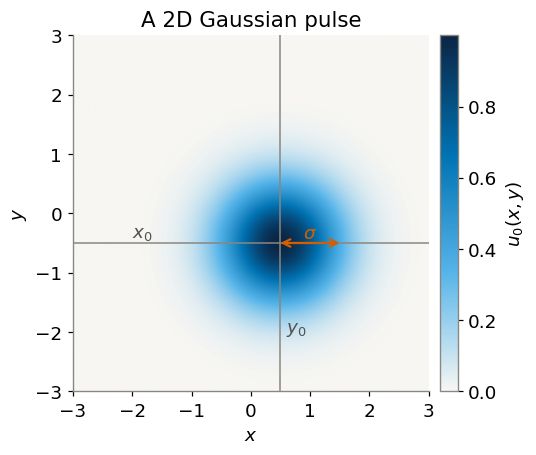

In [ ]:
# Plot of a 2D Gaussian pulse
gauss2d = Gaussian2D(width=1, amplitude=1, x0=0.5, y0=-0.5)
x = np.linspace(-3, 3, 400)
y = np.linspace(-3, 3, 400)
X, Y = np.meshgrid(x, y)
fig, ax = plt.subplots()
im = ax.imshow(gauss2d(X, Y), origin="lower", extent=(x[0], x[-1], y[0], y[-1]), cmap=SEQ_CMAP)
ax.set(xlabel="$x$", ylabel="$y$", title="A 2D Gaussian pulse")
ax.annotate("", xy=(gauss2d.x0 + gauss2d.width, gauss2d.y0), xytext=(gauss2d.x0, gauss2d.y0),
            arrowprops=dict(arrowstyle="<->", color=PALETTE[1], lw=1.5, shrinkA=0, shrinkB=0))
ax.text(gauss2d.x0 + gauss2d.width / 2, gauss2d.y0 + 0.08, r"$\sigma$", color=PALETTE[1], ha="center")
ax.axvline(gauss2d.x0, color="#898781", lw=1)
ax.axhline(gauss2d.y0, color="#898781", lw=1)
ax.text(-2, -0.4, "$x_0$", color="#52514e")
ax.text(0.6, -2, "$y_0$", color="#52514e")
ax.figure.colorbar(im, ax=ax, label="$u_0(x, y)$", pad=0.02)
plt.grid(False)
plt.show()

### Test on a simple case: Benjamin-Feir

## Part 2: Crank-Nicolson Solver

### Test on a simple case: Benjamin-Feir